# Post-Hoc Robustness Check: Subbasin-Balanced Hold-Outs

**Objective:** Check how much the hold-out score depends on *which area* ends up in the hold-out. The official hold-out (fold 4 of the `10km_subbasin` split) concentrates about half of the East Side Aquifer samples, our most contaminated subbasin, and scored lower than cross-validation (AUC 0.741 vs. 0.827).

**This is a post-hoc analysis, not a replacement for the official result.** It was designed *after* seeing the official hold-out score, and every well here, including the official hold-out wells, has already been used during the project. The official hold-out remains the result we report; this notebook only describes how much the score varies when the test area is drawn so that every subbasin is represented in proportion.

**Design (no new modeling decisions):**
1. Same data, features (`load_model_data(subbasin=True)`), 10 km grid cells, model (tuned random forest from the consolidated notebooks) and threshold (0.4) as `final_results.ipynb`.
2. Each repeat draws a new hold-out: within **each subbasin**, whole 10 km cells are picked at random until about 20% of that subbasin's samples are held out.
3. The remaining data are split into 4 spatial folds (whole cells, balanced on exceedance) for the hyperparameter search; the model is fit on them and scored once on that repeat's hold-out.
4. Several repeats with different random seeds show the range of hold-out scores.

**Runtime:** each repeat tunes two random forests; about 3–5 minutes per repeat.

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (roc_auc_score, brier_score_loss, precision_score, recall_score, f1_score,
                             root_mean_squared_error, r2_score)

from src.features.preprocessing import load_model_data
from src.evaluation import splits
from src.evaluation.make_splits import load_split
from src.models.evaluate import tuned

## 0. Settings

In [2]:
N_REPEATS = 5                 # number of subbasin-balanced hold-outs
HOLDOUT_SHARE = 0.20          # target share of each subbasin's samples in the hold-out
THRESHOLD = 0.4               # same threshold as final_results.ipynb
THRESHOLD_MG_L = 10

RF_GRID = {                   # same grid and search as the consolidated model notebooks
    "max_depth": [6, 8, 11, 15, None],
    "max_features": ["sqrt", 0.3, 0.5],
    "min_samples_leaf": [1, 5, 20],
}

# Official results (final_results.ipynb), for reference
OFFICIAL = {"cv_auc": 0.827, "holdout_auc": 0.741, "cv_brier_skill": 0.291, "holdout_brier_skill": 0.209,
            "cv_r2": 0.343, "holdout_r2": 0.170, "holdout_recall": 0.741, "holdout_precision": 0.586}

OUT_DIR = ROOT / "results" / "robustness"
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Data and the subbasin of each 10 km cell

Cells are the same 10 km cells used by the official split. Each cell is assigned to the subbasin where most of its samples are.

In [3]:
X, y, meta = load_model_data(subbasin=True)
FEATURES = list(X.columns)
data = load_split(pd.concat([meta, X], axis=1).assign(log_nitrate=y), split="10km_subbasin").reset_index(drop=True)
data["exceeds"] = (np.expm1(data["log_nitrate"]) > THRESHOLD_MG_L).astype(int)

subbasin_cols = [c for c in FEATURES if c.startswith("subbasin_")]
data["subbasin_name"] = (data[subbasin_cols].idxmax(axis=1).str.replace("subbasin_", "", regex=False)
                         .str.title().str.replace("Foot", "ft", regex=False))
cell_subbasin = data.groupby("cell")["subbasin_name"].agg(lambda s: s.value_counts().index[0])
cell_samples = data.groupby("cell").size()

summary = pd.DataFrame({"cells": cell_subbasin.value_counts(),
                        "samples": data["subbasin_name"].value_counts(),
                        "share_above_10": data.groupby("subbasin_name")["exceeds"].mean().round(2)})
display(summary.sort_values("samples", ascending=False))

,cells,samples,share_above_10
subbasin_name,,,
Forebay Aquifer,7.0,1501,0.54
180/400 ft Aquifer,4.0,977,0.22
Paso Robles Area,8.0,956,0.03
East Side Aquifer,5.0,696,0.60
Upper Valley Aquifer,11.0,563,0.48
Outside,14.0,327,0.03
Atascadero Area,3.0,242,0.10
Monterey,NaN,18,0.17


## 2. Draw subbasin-balanced hold-outs

Within each subbasin, cells are shuffled and added to the hold-out while that subbasin's held-out samples stay below the target share; a cell is always kept whole. Small subbasins with only a few cells may end up with slightly more or less than the target.

In [4]:
def balanced_holdout(seed):
    """Cells chosen so that each subbasin contributes about HOLDOUT_SHARE of its samples."""
    rng = np.random.default_rng(seed)
    chosen = []
    for name, cells_in in cell_subbasin.groupby(cell_subbasin):
        order = rng.permutation(cells_in.index.to_numpy())
        target = HOLDOUT_SHARE * cell_samples[order].sum()
        held = 0
        for cell in order:
            if held + cell_samples[cell] / 2 <= target:    # add the cell if at least half of it fits
                chosen.append(cell)
                held += cell_samples[cell]
    return data["cell"].isin(chosen).to_numpy()


holdouts = {seed: balanced_holdout(seed) for seed in range(N_REPEATS)}
balance = pd.DataFrame({f"repeat {s}": data[h].groupby("subbasin_name").size() / data.groupby("subbasin_name").size()
                        for s, h in holdouts.items()}).fillna(0)
balance.loc["All samples"] = [h.mean() for h in holdouts.values()]
balance.loc["Share above 10 mg/L (hold-out)"] = [data.loc[h, "exceeds"].mean() for h in holdouts.values()]
official = data["holdout"].to_numpy()
balance["official hold-out"] = list((data[official].groupby("subbasin_name").size()
                                     / data.groupby("subbasin_name").size()).reindex(balance.index[:-2]).fillna(0)) \
                               + [official.mean(), data.loc[official, "exceeds"].mean()]
print("Share of each subbasin's samples in the hold-out:")
display(balance.round(2))

Share of each subbasin's samples in the hold-out:


,repeat 0,repeat 1,repeat 2,repeat 3,repeat 4,official hold-out
subbasin_name,,,,,,
180/400 ft Aquifer,0.18,0.36,0.18,0.20,0.20,0.08
Atascadero Area,0.41,0.54,0.02,0.02,0.41,0.00
East Side Aquifer,0.14,0.31,0.14,0.22,0.20,0.49
Forebay Aquifer,0.17,0.21,0.24,0.24,0.24,0.15
Monterey,1.00,0.00,1.00,1.00,1.00,0.00
Outside,0.31,0.33,0.18,0.15,0.33,0.19
Paso Robles Area,0.20,0.31,0.20,0.23,0.28,0.20
Upper Valley Aquifer,0.25,0.24,0.22,0.26,0.24,0.23
All samples,0.20,0.29,0.19,0.22,0.25,0.19


## 3. Fit and score each repeat

For each repeat: 4 spatial folds on the remaining data for the hyperparameter search (same search as the model notebooks), one fit, one score on that repeat's hold-out.

In [5]:
def fit_search(make_search, dev, target, folds):
    search = make_search()
    search.fit(dev[FEATURES], dev[target], groups=folds)
    return search.best_estimator_


rows = []
for seed, is_holdout in holdouts.items():
    dev, test = data[~is_holdout].reset_index(drop=True), data[is_holdout].reset_index(drop=True)
    folds = splits.spatial_folds(dev["cell"], dev["exceeds"], n_splits=4, seed=seed)

    clf = fit_search(lambda: tuned(RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=1),
                                   RF_GRID, "neg_brier_score", n_iter=10), dev, "exceeds", folds)
    prob = clf.predict_proba(test[FEATURES])[:, 1]
    called = (prob >= THRESHOLD).astype(int)
    base_rate = dev["exceeds"].mean()

    reg = fit_search(lambda: tuned(RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=1),
                                   RF_GRID, "neg_root_mean_squared_error", n_iter=10), dev, "log_nitrate", folds)
    pred = reg.predict(test[FEATURES])
    dummy = DummyRegressor().fit(dev[FEATURES], dev["log_nitrate"]).predict(test[FEATURES])

    rows.append({
        "repeat": seed, "holdout_samples": len(test), "holdout_share_above_10": test["exceeds"].mean(),
        "auc": roc_auc_score(test["exceeds"], prob),
        "brier_skill": 1 - brier_score_loss(test["exceeds"], prob)
                       / brier_score_loss(test["exceeds"], np.full(len(test), base_rate)),
        "recall": recall_score(test["exceeds"], called), "precision": precision_score(test["exceeds"], called),
        "f1": f1_score(test["exceeds"], called),
        "rmse_log": root_mean_squared_error(test["log_nitrate"], pred),
        "dummy_rmse_log": root_mean_squared_error(test["log_nitrate"], dummy),
        "r2": r2_score(test["log_nitrate"], pred),
    })
    print(f"Repeat {seed}: AUC {rows[-1]['auc']:.3f} | R² {rows[-1]['r2']:.3f} | "
          f"{len(test):,} hold-out samples, {rows[-1]['holdout_share_above_10']:.0%} above 10 mg/L")

robustness = pd.DataFrame(rows)
robustness.to_csv(OUT_DIR / "subbasin_balanced_holdouts.csv", index=False)
display(robustness.round(3))

Repeat 0: AUC 0.867 | R² 0.453 | 1,076 hold-out samples, 28% above 10 mg/L
Repeat 1: AUC 0.812 | R² 0.290 | 1,550 hold-out samples, 31% above 10 mg/L
Repeat 2: AUC 0.800 | R² 0.324 | 1,018 hold-out samples, 33% above 10 mg/L
Repeat 3: AUC 0.865 | R² 0.387 | 1,146 hold-out samples, 29% above 10 mg/L
Repeat 4: AUC 0.844 | R² 0.370 | 1,325 hold-out samples, 26% above 10 mg/L


,repeat,holdout_samples,holdout_share_above_10,auc,brier_skill,recall,precision,f1,rmse_log,dummy_rmse_log,r2
0,0,1076,0.283,0.867,0.364,0.839,0.637,0.724,0.923,1.289,0.453
1,1,1550,0.311,0.812,0.253,0.685,0.591,0.635,0.962,1.145,0.290
2,2,1018,0.326,0.800,0.224,0.771,0.575,0.659,0.940,1.145,0.324
3,3,1146,0.286,0.865,0.307,0.893,0.535,0.669,0.987,1.283,0.387
4,4,1325,0.264,0.844,0.302,0.823,0.543,0.655,0.927,1.189,0.370


## 4. Summary and comparison with the official results

,balanced hold-outs (mean),balanced hold-outs (min),balanced hold-outs (max),official cross-validation,official hold-out
auc,0.838,0.800,0.867,0.827,0.741
brier_skill,0.290,0.224,0.364,0.291,0.209
recall,0.802,0.685,0.893,NaN,0.741
precision,0.576,0.535,0.637,NaN,0.586
r2,0.365,0.290,0.453,0.343,0.170


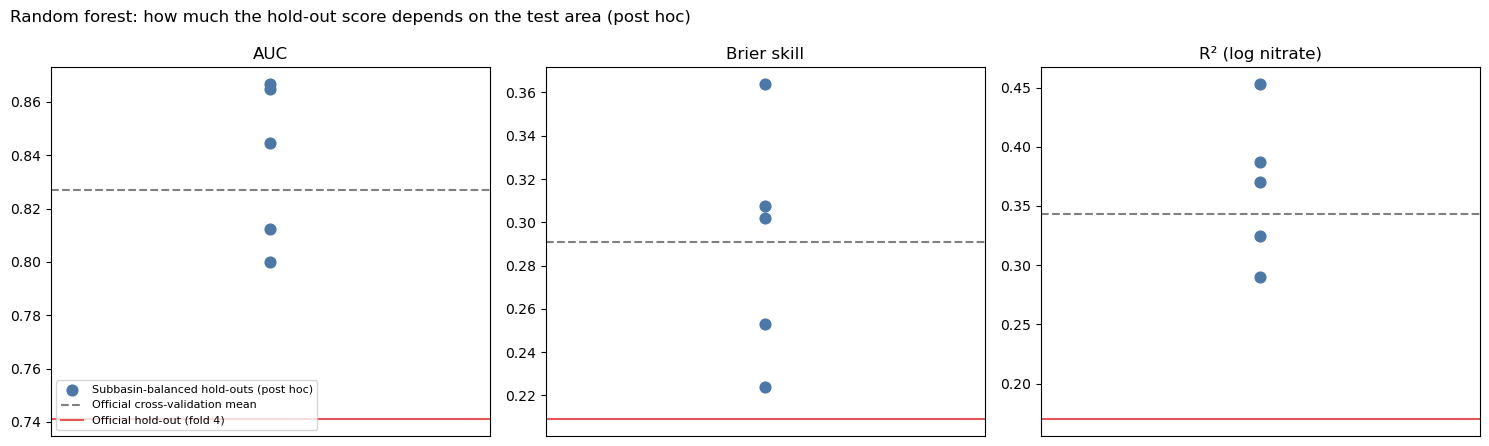

In [6]:
metrics = ["auc", "brier_skill", "recall", "precision", "r2"]
comparison = pd.DataFrame({
    "balanced hold-outs (mean)": robustness[metrics].mean(),
    "balanced hold-outs (min)": robustness[metrics].min(),
    "balanced hold-outs (max)": robustness[metrics].max(),
    "official cross-validation": [OFFICIAL["cv_auc"], OFFICIAL["cv_brier_skill"], np.nan, np.nan, OFFICIAL["cv_r2"]],
    "official hold-out": [OFFICIAL["holdout_auc"], OFFICIAL["holdout_brier_skill"],
                          OFFICIAL["holdout_recall"], OFFICIAL["holdout_precision"], OFFICIAL["holdout_r2"]],
})
display(comparison.round(3))

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (metric, name) in zip(axs, [("auc", "AUC"), ("brier_skill", "Brier skill"), ("r2", "R² (log nitrate)")]):
    ax.scatter(np.zeros(len(robustness)), robustness[metric], s=60, color="#4c78a8", zorder=3,
               label="Subbasin-balanced hold-outs (post hoc)")
    ax.axhline(OFFICIAL[f"cv_{metric}"], color="gray", linestyle="--", label="Official cross-validation mean")
    ax.axhline(OFFICIAL[f"holdout_{metric}"], color="#e45756", linestyle="-", label="Official hold-out (fold 4)")
    ax.set_xticks([])
    ax.set_title(name)
axs[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Random forest: how much the hold-out score depends on the test area (post hoc)", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(OUT_DIR / "subbasin_balanced_holdouts.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Conclusions

- **Balanced hold-outs reproduce cross-validation performance.** Across 5 subbasin-balanced hold-outs, the random forest's AUC ranged from 0.800 to 0.867 (mean 0.838), close to the cross-validation mean (0.827). Brier skill (mean 0.290 vs. 0.291) and R² for log nitrate (mean 0.365 vs. 0.343) also match cross-validation.
- **The official hold-out is below every balanced repeat** (AUC 0.741 vs. a minimum of 0.800; R² 0.170 vs. a minimum of 0.290). This is consistent with its test area being harder: it contains about half of the East Side Aquifer samples, our most contaminated subbasin, and 42% of its samples exceed 10 mg/L versus about 30% elsewhere.
- **At the 0.4 threshold**, the balanced hold-outs detect 69–89% of exceeding samples (mean 80%) with 54–64% precision, similar to the official hold-out's 74% recall and 59% precision.
- **Interpretation:** the model generalizes to unseen areas about as well as cross-validation suggests when every subbasin is represented, but it performs worse where a heavily contaminated subbasin is under-represented in training.
- **Caveat:** this check was designed after seeing the official result and reuses wells already used in the project, so it describes variability; it is not an independent test. The official hold-out score is the one we report, alongside cross-validation. A clean test of a subbasin-balanced design would need new data (e.g., 2026 samples).